# Bearing Health Monitoring and Early Degradation Detection
This notebook builds a clean, defensible anomaly-detection pipeline on the IMS / NASA bearing run-to-failure dataset. The final goal is to model early healthy behavior and detect sustained deviation over time.

**Final configuration used in this notebook**
- One file = one time point
- One channel = one signal
- Channel used: `channel_idx = 1`
- Healthy baseline = first 10% of files
- Final model = Isolation Forest on selected vibration features

In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import detrend
from scipy.stats import kurtosis, skew
from scipy.fft import rfft, rfftfreq

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

## 2. Dataset path and one-file inspection
We first verify the folder, file ordering, and the raw shape of one IMS file.

In [4]:
base_path = Path("../data/raw/1st_test")

file_list = sorted([f for f in os.listdir(base_path) if not f.startswith(".")])

print("Number of files:", len(file_list))
print("First 5 files:")
for f in file_list[:5]:
    print(f)

Number of files: 2156
First 5 files:
2003.10.22.12.06.24
2003.10.22.12.09.13
2003.10.22.12.14.13
2003.10.22.12.19.13
2003.10.22.12.24.13


In [5]:
sample_file = base_path / file_list[0]
sample_data = np.loadtxt(sample_file)

print("Sample file:", sample_file.name)
print("Shape:", sample_data.shape)
print("First 5 rows:")
print(sample_data[:5])

Sample file: 2003.10.22.12.06.24
Shape: (20480, 8)
First 5 rows:
[[-0.022 -0.039 -0.183 -0.054 -0.105 -0.134 -0.129 -0.142]
 [-0.105 -0.017 -0.164 -0.183 -0.049  0.029 -0.115 -0.122]
 [-0.183 -0.098 -0.195 -0.125 -0.005 -0.007 -0.171 -0.071]
 [-0.178 -0.161 -0.159 -0.178 -0.1   -0.115 -0.112 -0.078]
 [-0.208 -0.129 -0.261 -0.098 -0.151 -0.205 -0.063 -0.066]]


## 3. Choose one sensor channel and inspect the raw signal
We start with a single channel to keep the pipeline interpretable and avoid mixing sensor behavior.

In [6]:
channel_idx = 1

raw_signal = sample_data[:, channel_idx]

print("Selected channel:", channel_idx)
print("Raw signal shape:", raw_signal.shape)

Selected channel: 1
Raw signal shape: (20480,)


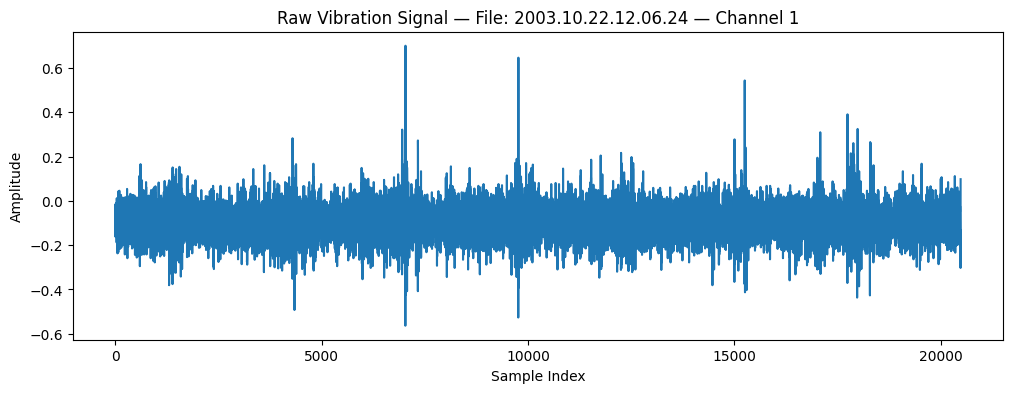

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(raw_signal)
plt.title(f"Raw Vibration Signal — File: {sample_file.name} — Channel {channel_idx}")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.show()

## 4. Preprocess one 1D vibration signal
We detrend and center the signal, but we do **not** normalize each file to unit variance. That preserves amplitude information that may carry degradation signal.

In [8]:
def preprocess_signal(signal_1d):
    """
    Preprocess one 1D vibration signal.

    Steps:
    1. Remove linear trend over time
    2. Remove any remaining mean offset

    Important:
    We do NOT normalize each file to unit std,
    because that would destroy amplitude information
    that may be useful for degradation tracking.
    """
    x = np.asarray(signal_1d).astype(float)

    x_detrended = detrend(x)
    x_centered = x_detrended - np.mean(x_detrended)

    return x_centered

In [9]:
signal_clean = preprocess_signal(raw_signal)

print("Preprocessed signal shape:", signal_clean.shape)

Preprocessed signal shape: (20480,)


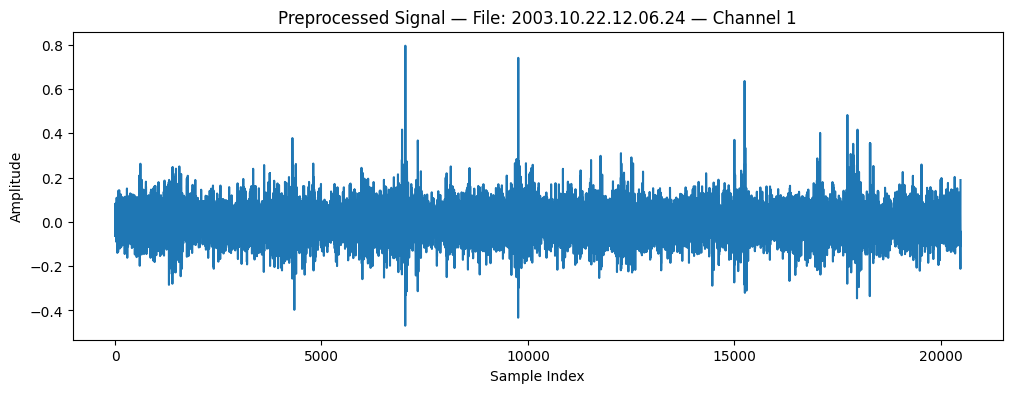

In [10]:
plt.figure(figsize=(12, 4))
plt.plot(signal_clean)
plt.title(f"Preprocessed Signal — File: {sample_file.name} — Channel {channel_idx}")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.show()

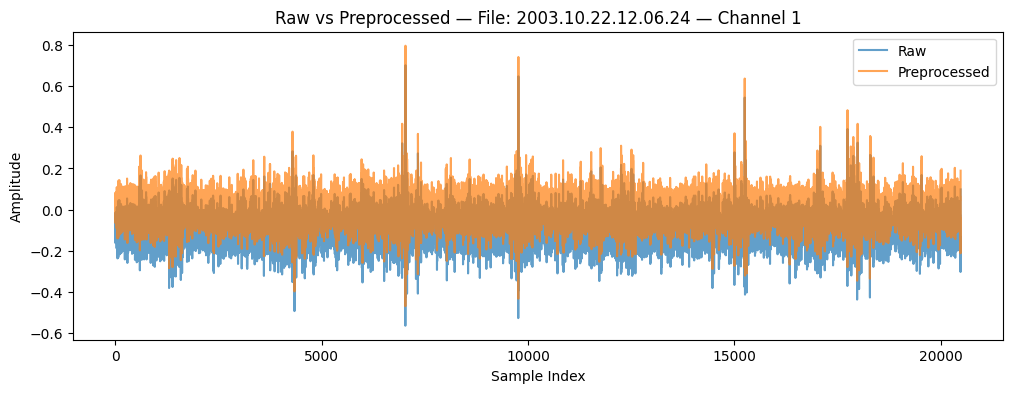

In [11]:
plt.figure(figsize=(12, 4))
plt.plot(raw_signal, label="Raw", alpha=0.7)
plt.plot(signal_clean, label="Preprocessed", alpha=0.7)
plt.title(f"Raw vs Preprocessed — File: {sample_file.name} — Channel {channel_idx}")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.legend()
plt.show()

## 5. Extract one feature vector from one file
Each file becomes one row of time-domain and frequency-domain features.
## Data structure and feature extraction

In the IMS dataset, one bearing lifetime is represented by many files in chronological order.

Each file is one short vibration measurement snapshot with shape (20480, 8):
- 20480 rows = time samples within that snapshot
- 8 columns = simultaneous sensor channels

In this notebook, one channel is selected and analyzed consistently across all files. Each file is treated as one time point in the bearing lifetime, and each selected signal is converted into one scalar feature vector.

In [12]:
def extract_features(signal_1d, fs=20000):
    """
    Extract scalar time-domain and frequency-domain features
    from one preprocessed 1D vibration signal.
    """
    x = np.asarray(signal_1d).astype(float)

    # ----------------------------
    # Time-domain features
    # ----------------------------
    mean_val = np.mean(x)
    std_val = np.std(x)
    rms_val = np.sqrt(np.mean(x**2))
    max_abs = np.max(np.abs(x))
    peak_to_peak = np.ptp(x)
    kurt_val = kurtosis(x, fisher=False, bias=False)
    skew_val = skew(x, bias=False)
    crest_factor = max_abs / rms_val if rms_val > 0 else 0.0

    # ----------------------------
    # Frequency-domain features
    # ----------------------------
    spectrum = np.abs(rfft(x))
    freqs = rfftfreq(len(x), d=1/fs)

    spec_sum = np.sum(spectrum)
    if spec_sum == 0:
        spec_sum = 1e-12

    # Dominant frequency: ignore DC bin if possible
    if len(spectrum) > 1:
        dom_idx = np.argmax(spectrum[1:]) + 1
    else:
        dom_idx = 0
    dominant_freq = freqs[dom_idx]

    spectral_centroid = np.sum(freqs * spectrum) / spec_sum
    spectral_bandwidth = np.sqrt(
        np.sum(((freqs - spectral_centroid) ** 2) * spectrum) / spec_sum
    )

    # Band energies
    band_0_1k = np.sum(spectrum[(freqs >= 0) & (freqs < 1000)])
    band_1_3k = np.sum(spectrum[(freqs >= 1000) & (freqs < 3000)])
    band_3_5k = np.sum(spectrum[(freqs >= 3000) & (freqs < 5000)])
    band_5_10k = np.sum(spectrum[(freqs >= 5000) & (freqs < 10000)])

    return {
        "mean": mean_val,
        "std": std_val,
        "rms": rms_val,
        "max_abs": max_abs,
        "peak_to_peak": peak_to_peak,
        "kurtosis": kurt_val,
        "skewness": skew_val,
        "crest_factor": crest_factor,
        "dominant_freq": dominant_freq,
        "spec_centroid": spectral_centroid,
        "spec_bandwidth": spectral_bandwidth,
        "band_0_1k": band_0_1k,
        "band_1_3k": band_1_3k,
        "band_3_5k": band_3_5k,
        "band_5_10k": band_5_10k,
    }

In [13]:
sample_features = extract_features(signal_clean, fs=20000)
sample_features

{'mean': np.float64(-3.903127820947816e-19),
 'std': np.float64(0.07062693080963899),
 'rms': np.float64(0.07062693080963899),
 'max_abs': np.float64(0.795819741543034),
 'peak_to_peak': np.float64(1.2649991211710772),
 'kurtosis': np.float64(6.064337079348367),
 'skewness': np.float64(0.22064372491695095),
 'crest_factor': np.float64(11.26793607509308),
 'dominant_freq': np.float64(986.328125),
 'spec_centroid': np.float64(4667.822417273564),
 'spec_bandwidth': np.float64(2958.9031223943366),
 'band_0_1k': np.float64(9327.173632932896),
 'band_1_3k': np.float64(18722.469057226),
 'band_3_5k': np.float64(19216.825117936933),
 'band_5_10k': np.float64(32751.834137382953)}

In [14]:
df_sample_features = pd.DataFrame([sample_features])
df_sample_features

,mean,std,rms,max_abs,peak_to_peak,kurtosis,skewness,crest_factor,dominant_freq,spec_centroid,spec_bandwidth,band_0_1k,band_1_3k,band_3_5k,band_5_10k
0,-3.903128e-19,0.070627,0.070627,0.79582,1.264999,6.064337,0.220644,11.267936,986.328125,4667.822417,2958.903122,9327.173633,18722.469057,19216.825118,32751.834137


In [15]:
print("Feature columns:")
print(df_sample_features.columns.tolist())

print("\nDtypes:")
print(df_sample_features.dtypes)

Feature columns:
['mean', 'std', 'rms', 'max_abs', 'peak_to_peak', 'kurtosis', 'skewness', 'crest_factor', 'dominant_freq', 'spec_centroid', 'spec_bandwidth', 'band_0_1k', 'band_1_3k', 'band_3_5k', 'band_5_10k']

Dtypes:
mean              float64
std               float64
rms               float64
max_abs           float64
peak_to_peak      float64
kurtosis          float64
skewness          float64
crest_factor      float64
dominant_freq     float64
spec_centroid     float64
spec_bandwidth    float64
band_0_1k         float64
band_1_3k         float64
band_3_5k         float64
band_5_10k        float64
dtype: object


In [16]:
df_sample_features.T.rename(columns={0: "value"})

,value
mean,-3.903128e-19
std,7.062693e-02
rms,7.062693e-02
max_abs,7.958197e-01
peak_to_peak,1.264999e+00
kurtosis,6.064337e+00
skewness,2.206437e-01
crest_factor,1.126794e+01
dominant_freq,9.863281e+02
spec_centroid,4.667822e+03


## 6. Process all files into one feature table
This creates the main dataset: one row per file, one column per feature.

In [17]:
def process_file(file_path, channel_idx=0, fs=20000):
    """
    Process one IMS file into one feature dictionary.

    Steps:
    - load file
    - select one channel
    - preprocess signal
    - extract scalar features
    - attach filename
    """
    data = np.loadtxt(file_path)
    signal = data[:, channel_idx]
    signal_clean = preprocess_signal(signal)

    feats = extract_features(signal_clean, fs=fs)
    feats["file_name"] = file_path.name

    return feats

In [18]:
test_row = process_file(sample_file, channel_idx=channel_idx, fs=20000)
test_row

{'mean': np.float64(-3.903127820947816e-19),
 'std': np.float64(0.07062693080963899),
 'rms': np.float64(0.07062693080963899),
 'max_abs': np.float64(0.795819741543034),
 'peak_to_peak': np.float64(1.2649991211710772),
 'kurtosis': np.float64(6.064337079348367),
 'skewness': np.float64(0.22064372491695095),
 'crest_factor': np.float64(11.26793607509308),
 'dominant_freq': np.float64(986.328125),
 'spec_centroid': np.float64(4667.822417273564),
 'spec_bandwidth': np.float64(2958.9031223943366),
 'band_0_1k': np.float64(9327.173632932896),
 'band_1_3k': np.float64(18722.469057226),
 'band_3_5k': np.float64(19216.825117936933),
 'band_5_10k': np.float64(32751.834137382953),
 'file_name': '2003.10.22.12.06.24'}

In [19]:
feature_rows = []

for i, fname in enumerate(file_list):
    file_path = base_path / fname
    row = process_file(file_path, channel_idx=channel_idx, fs=20000)
    row["file_index"] = i
    feature_rows.append(row)

    if (i + 1) % 200 == 0:
        print(f"Processed {i + 1}/{len(file_list)} files")

Processed 200/2156 files
Processed 400/2156 files
Processed 600/2156 files
Processed 800/2156 files
Processed 1000/2156 files
Processed 1200/2156 files
Processed 1400/2156 files
Processed 1600/2156 files
Processed 1800/2156 files
Processed 2000/2156 files


In [20]:
df_features = pd.DataFrame(feature_rows)

In [21]:
print("Shape:", df_features.shape)
df_features.head()

Shape: (2156, 17)


,mean,std,rms,max_abs,peak_to_peak,kurtosis,skewness,crest_factor,dominant_freq,spec_centroid,spec_bandwidth,band_0_1k,band_1_3k,band_3_5k,band_5_10k,file_name,file_index
0,-3.903128e-19,0.070627,0.070627,0.795820,1.264999,6.064337,0.220644,11.267936,986.328125,4667.822417,2958.903122,9327.173633,18722.469057,19216.825118,32751.834137,2003.10.22.12.06.24,0
1,-8.673617e-19,0.069529,0.069529,0.675020,1.072279,5.002117,0.126444,9.708459,986.328125,4610.209560,2943.385457,9476.884880,18693.603191,19107.993375,31826.729121,2003.10.22.12.09.13,1
2,-3.469447e-19,0.069458,0.069458,0.644954,1.017558,4.970816,0.150941,9.285492,986.328125,4586.884310,2950.779209,9238.167990,18847.935559,18832.061177,30759.722926,2003.10.22.12.14.13,2
3,-2.602085e-19,0.071249,0.071249,0.627779,1.008999,4.737037,0.097761,8.811082,986.328125,4628.377974,2947.896394,9411.176211,19314.040238,19420.606029,32467.416987,2003.10.22.12.19.13,3
4,-1.517883e-19,0.072140,0.072140,0.480452,0.923629,4.184360,0.093773,6.659992,986.328125,4596.047817,2947.796830,9836.533777,19346.679961,19736.163780,32128.886812,2003.10.22.12.24.13,4


In [22]:
print(df_features.columns.tolist())

['mean', 'std', 'rms', 'max_abs', 'peak_to_peak', 'kurtosis', 'skewness', 'crest_factor', 'dominant_freq', 'spec_centroid', 'spec_bandwidth', 'band_0_1k', 'band_1_3k', 'band_3_5k', 'band_5_10k', 'file_name', 'file_index']


In [23]:
df_features.dtypes

mean              float64
std               float64
rms               float64
max_abs           float64
peak_to_peak      float64
kurtosis          float64
skewness          float64
crest_factor      float64
dominant_freq     float64
spec_centroid     float64
spec_bandwidth    float64
band_0_1k         float64
band_1_3k         float64
band_3_5k         float64
band_5_10k        float64
file_name          object
file_index          int64
dtype: object

In [24]:
df_features.isna().sum()

mean              0
std               0
rms               0
max_abs           0
peak_to_peak      0
kurtosis          0
skewness          0
crest_factor      0
dominant_freq     0
spec_centroid     0
spec_bandwidth    0
band_0_1k         0
band_1_3k         0
band_3_5k         0
band_5_10k        0
file_name         0
file_index        0
dtype: int64

In [25]:
df_features.describe()

,mean,std,rms,max_abs,peak_to_peak,kurtosis,skewness,crest_factor,dominant_freq,spec_centroid,spec_bandwidth,band_0_1k,band_1_3k,band_3_5k,band_5_10k,file_index
count,2.156000e+03,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000,2156.000000
mean,-1.185029e-20,0.088972,0.088972,0.651291,1.162620,4.104552,0.066454,7.335820,987.396184,4583.792876,2881.165123,12342.606447,24065.325221,26248.514456,41835.301935,1077.500000
std,1.320260e-18,0.005293,0.005293,0.087700,0.131920,0.308090,0.040822,1.006483,0.587926,56.092785,32.245780,852.668733,1693.602871,2135.832798,2847.790735,622.527911
min,-3.361027e-18,0.069297,0.069297,0.427539,0.827584,3.266091,-0.072495,4.701054,985.351562,4382.557659,2772.944775,8975.674474,18158.164909,18832.061177,30692.344634,0.000000
25%,-9.974660e-19,0.087869,0.087869,0.589288,1.070199,3.893002,0.039737,6.630548,987.304688,4543.447581,2858.979284,12128.565729,23457.668504,25742.785673,41368.315716,538.750000
50%,0.000000e+00,0.090195,0.090195,0.648274,1.151054,4.067959,0.064621,7.263917,987.304688,4583.090535,2875.929649,12478.629081,24208.567794,26756.526636,42080.350710,1077.500000
75%,9.107298e-19,0.091826,0.091826,0.703930,1.247553,4.274161,0.093135,7.939414,987.304688,4619.039046,2896.910909,12783.851280,25131.063342,27602.309047,42937.449460,1616.250000
max,3.382711e-18,0.106986,0.106986,1.141599,1.767534,6.064337,0.221074,12.061829,995.117188,4769.804089,2975.257643,15612.159656,31547.228041,32453.077144,50024.472553,2155.000000


## 7. Inspect raw feature trends before modeling
We visualize candidate features before fitting any anomaly model.

In [26]:
feature_cols = [
    col for col in df_features.columns
    if col not in ["file_name", "file_index"]
]

print("Feature columns used for analysis:")
print(feature_cols)

Feature columns used for analysis:
['mean', 'std', 'rms', 'max_abs', 'peak_to_peak', 'kurtosis', 'skewness', 'crest_factor', 'dominant_freq', 'spec_centroid', 'spec_bandwidth', 'band_0_1k', 'band_1_3k', 'band_3_5k', 'band_5_10k']


In [27]:
def plot_feature_trend(df, feature_name, smooth_window=25):
    """
    Plot one feature over file index.

    - raw values are shown lightly
    - rolling mean is shown on top for visual trend only

    smooth_window:
        number of files used in trailing moving average
    """
    x = df["file_index"]
    y = df[feature_name]

    y_smooth = y.rolling(window=smooth_window, min_periods=1).mean()

    plt.figure(figsize=(12, 4))
    plt.plot(x, y, alpha=0.35, label=f"{feature_name} (raw)")
    plt.plot(x, y_smooth, linewidth=2, label=f"{feature_name} (rolling mean, window={smooth_window})")
    plt.title(f"{feature_name} over file index — Channel {channel_idx}")
    plt.xlabel("File Index")
    plt.ylabel(feature_name)
    plt.legend()
    plt.show()

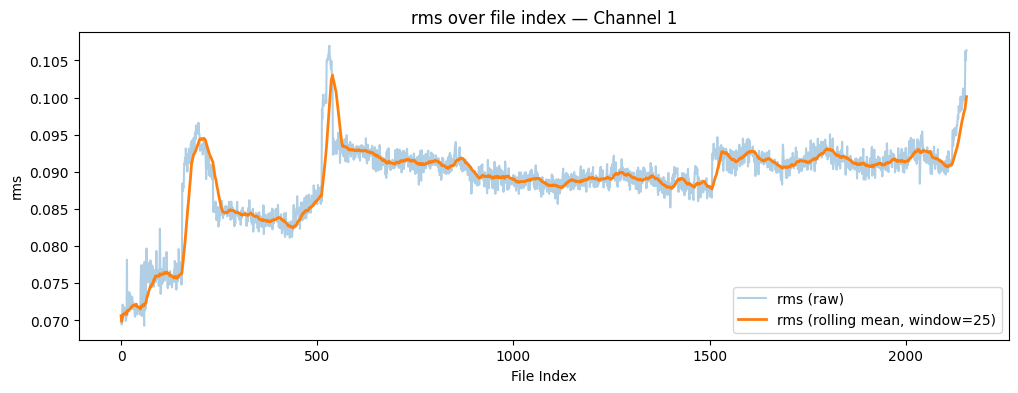

In [28]:
plot_feature_trend(df_features, "rms", smooth_window=25)

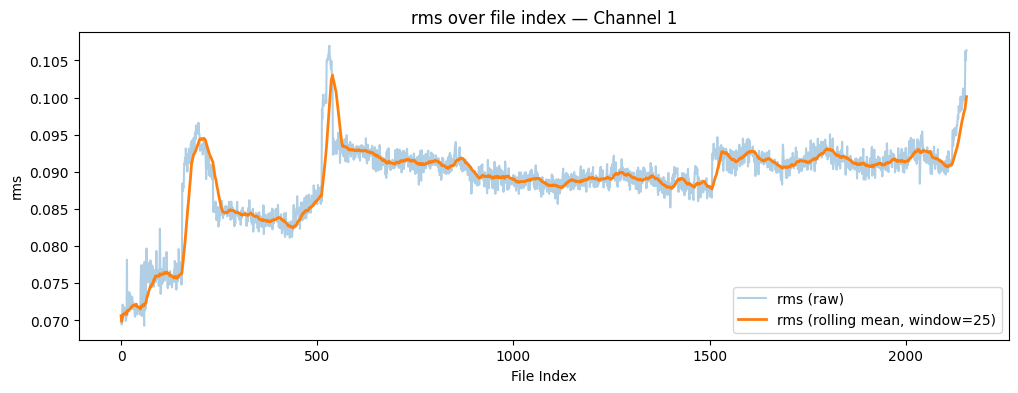

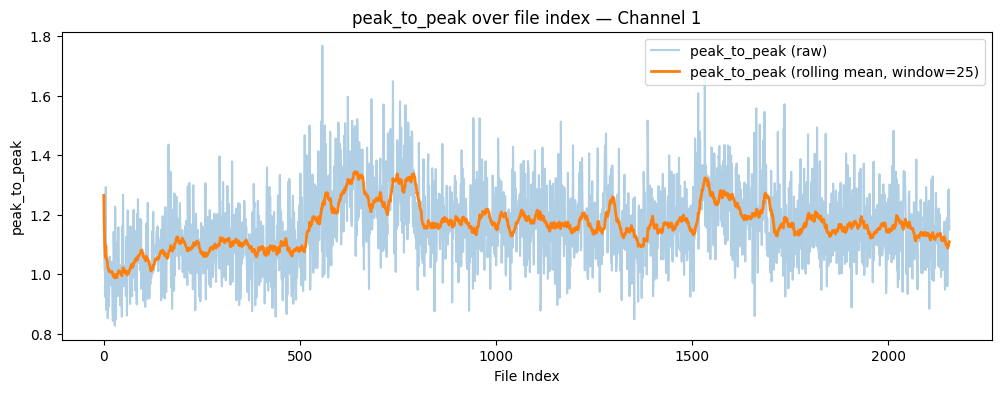

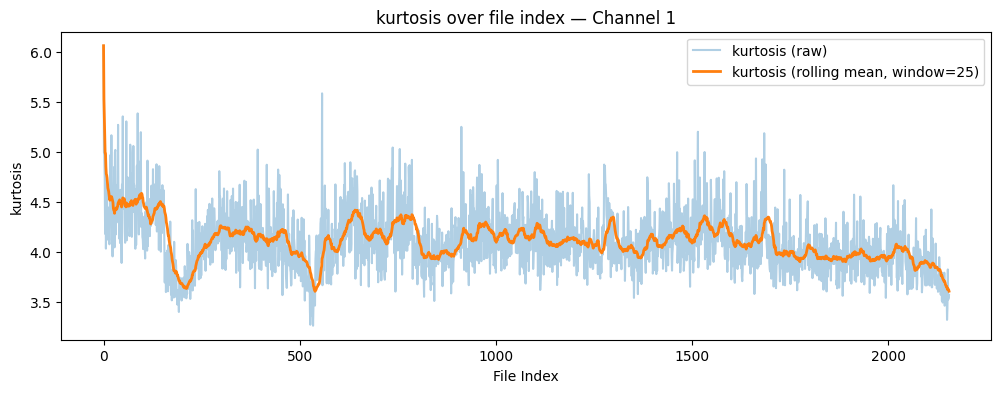

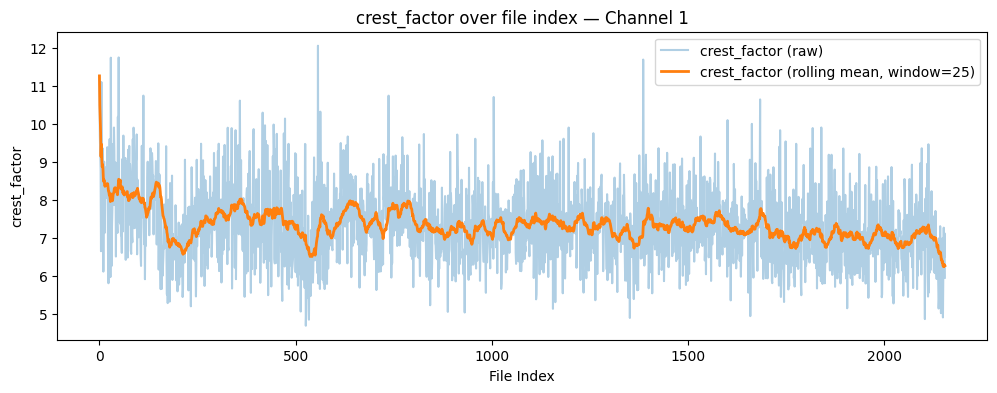

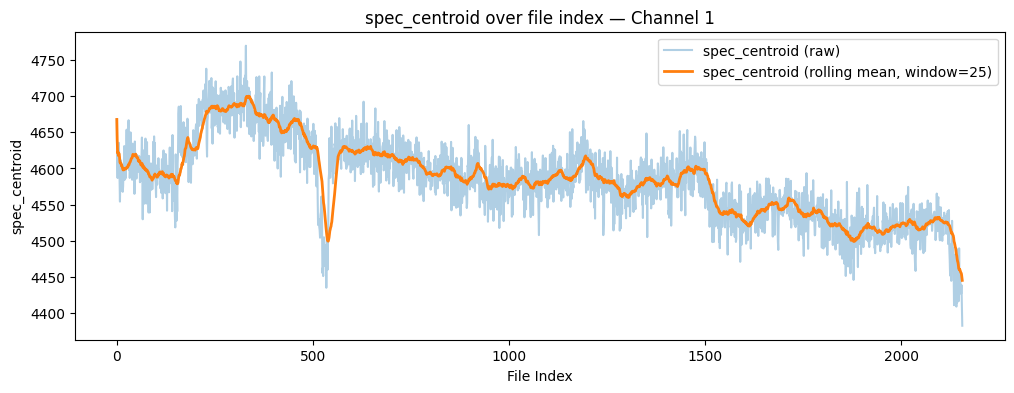

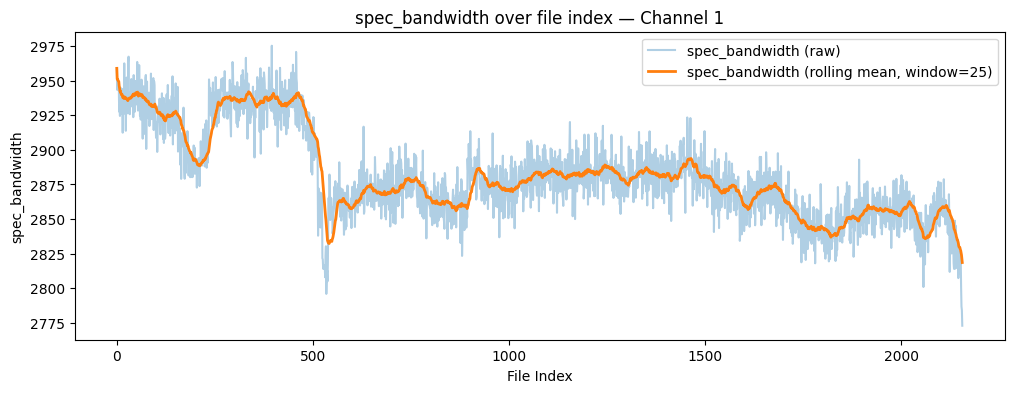

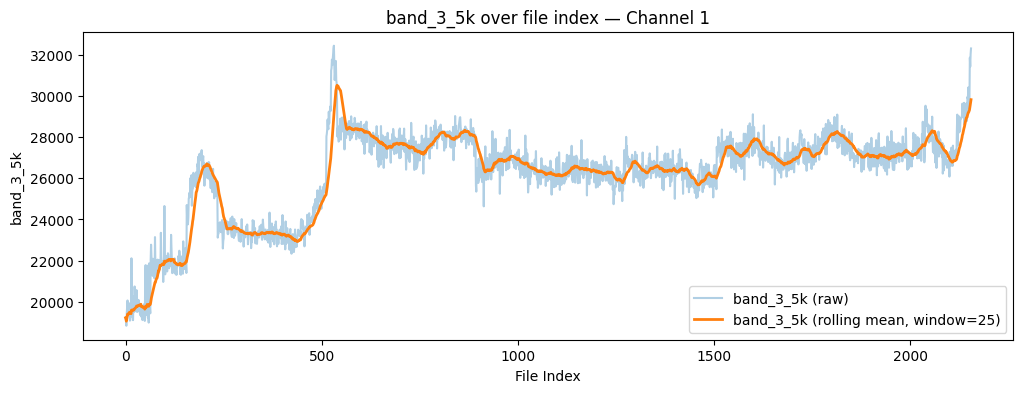

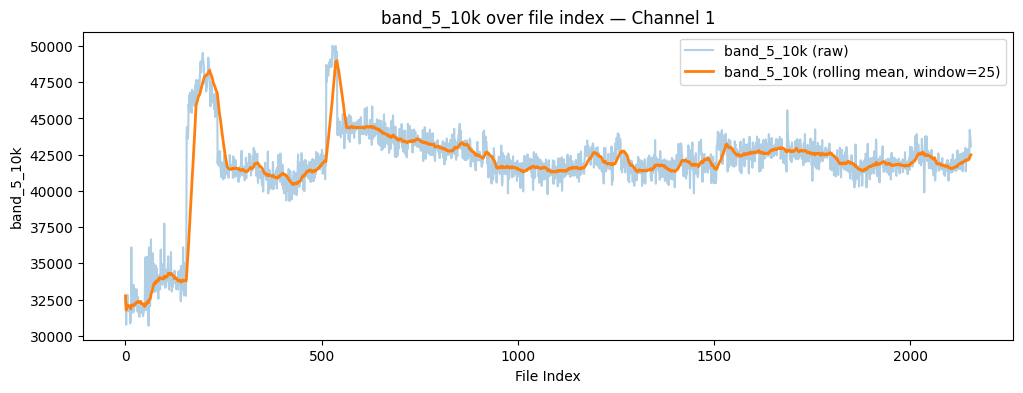

In [29]:
features_to_inspect = [
    "rms",
    "peak_to_peak",
    "kurtosis",
    "crest_factor",
    "spec_centroid",
    "spec_bandwidth",
    "band_3_5k",
    "band_5_10k",
]

for feat in features_to_inspect:
    plot_feature_trend(df_features, feat, smooth_window=25)

In [30]:
n_files = len(df_features)
n_segment = max(1, int(0.10 * n_files))

early_df = df_features.iloc[:n_segment]
late_df = df_features.iloc[-n_segment:]

comparison_rows = []

for feat in features_to_inspect:
    early_mean = early_df[feat].mean()
    late_mean = late_df[feat].mean()

    if abs(early_mean) > 1e-12:
        rel_change_pct = 100 * (late_mean - early_mean) / abs(early_mean)
    else:
        rel_change_pct = np.nan

    comparison_rows.append({
        "feature": feat,
        "early_mean": early_mean,
        "late_mean": late_mean,
        "relative_change_pct": rel_change_pct
    })

df_comparison = pd.DataFrame(comparison_rows)
df_comparison

,feature,early_mean,late_mean,relative_change_pct
0,rms,0.079508,0.092934,16.887183
1,peak_to_peak,1.053081,1.142559,8.496746
2,kurtosis,4.269040,3.890549,-8.865952
3,crest_factor,7.775924,6.933471,-10.834129
4,spec_centroid,4608.054384,4511.630507,-2.092507
5,spec_bandwidth,2922.100949,2848.124402,-2.531622
6,band_3_5k,22398.163507,27733.369861,23.819838
7,band_5_10k,37096.332701,42032.755473,13.307037


In [31]:
df_comparison["abs_relative_change_pct"] = df_comparison["relative_change_pct"].abs()
df_comparison.sort_values("abs_relative_change_pct", ascending=False)

,feature,early_mean,late_mean,relative_change_pct,abs_relative_change_pct
6,band_3_5k,22398.163507,27733.369861,23.819838,23.819838
0,rms,0.079508,0.092934,16.887183,16.887183
7,band_5_10k,37096.332701,42032.755473,13.307037,13.307037
3,crest_factor,7.775924,6.933471,-10.834129,10.834129
2,kurtosis,4.269040,3.890549,-8.865952,8.865952
1,peak_to_peak,1.053081,1.142559,8.496746,8.496746
5,spec_bandwidth,2922.100949,2848.124402,-2.531622,2.531622
4,spec_centroid,4608.054384,4511.630507,-2.092507,2.092507


## 8. Select final features and define the healthy baseline
We keep the strongest features and define healthy behavior using the first 10% of files.
## Why these final features?

The final model uses four features that gave the clearest and most interpretable early-to-late change over the bearing lifetime:

- **RMS**: tracks overall vibration energy / typical amplitude level
- **Peak-to-peak amplitude**: tracks the total signal range and extreme excursions
- **3–5 kHz band energy**: tracks growth in mid-high frequency vibration content
- **5–10 kHz band energy**: tracks growth in higher-frequency vibration content

Together, these features capture both:
- increasing overall vibration magnitude
- increasing high-frequency activity associated with degradation

The sampling frequency is fs = 20,000 Hz, so by the Nyquist theorem the highest resolvable frequency is 10,000 Hz. Therefore, the usable one-sided FFT range is 0 to 10 kHz.

To summarize this spectrum in an interpretable way, the frequency axis was divided into broad bands, and band energy was computed as the summed spectral magnitude over each interval.

The 3–5 kHz and 5–10 kHz bands were retained because, within the physically observable Nyquist range, they showed the strongest and most consistent early-to-late change across the run. These bands are therefore justified as informative spectral summary regions, not as exact fault-frequency bands derived from bearing geometry.

In [32]:
selected_features = [
    "rms",
    "peak_to_peak",
    "band_3_5k",
    "band_5_10k",
]

print("Selected features for first clean model:")
print(selected_features)

Selected features for first clean model:
['rms', 'peak_to_peak', 'band_3_5k', 'band_5_10k']


In [33]:
X_raw = df_features[selected_features].copy()

print("Shape of raw modeling matrix:", X_raw.shape)
X_raw.head()

Shape of raw modeling matrix: (2156, 4)


,rms,peak_to_peak,band_3_5k,band_5_10k
0,0.070627,1.264999,19216.825118,32751.834137
1,0.069529,1.072279,19107.993375,31826.729121
2,0.069458,1.017558,18832.061177,30759.722926
3,0.071249,1.008999,19420.606029,32467.416987
4,0.072140,0.923629,19736.163780,32128.886812


In [34]:
healthy_fraction = 0.10
n_healthy = int(len(df_features) * healthy_fraction)

print("Total files:", len(df_features))
print("Healthy baseline fraction:", healthy_fraction)
print("Number of healthy baseline files:", n_healthy)

Total files: 2156
Healthy baseline fraction: 0.1
Number of healthy baseline files: 215


In [35]:
X_healthy_raw = X_raw.iloc[:n_healthy].copy()

print("Healthy baseline shape:", X_healthy_raw.shape)
print("All-data shape:", X_raw.shape)

Healthy baseline shape: (215, 4)
All-data shape: (2156, 4)


## 9. Scale features relative to the healthy baseline

At this stage, each file has already been converted into one feature vector in R^4:

- RMS
- peak-to-peak amplitude
- 3–5 kHz band energy
- 5–10 kHz band energy

These features live on very different numerical scales. For example, RMS is small in magnitude, while spectral band energies are much larger. If we do not scale them, large-magnitude features can dominate the geometry of the data simply because of units.

To avoid this, each feature is standardized using statistics computed from the healthy baseline only. For each feature j, we compute:

z_ij = (x_ij - mu_j) / sigma_j

where mu_j and sigma_j are the healthy-baseline mean and standard deviation of feature j.

This means each scaled feature value is measured in healthy-baseline standard deviations. The scaler is fit only on the healthy baseline so that degraded data does not contaminate the definition of normal behavior.

In [36]:
scaler = StandardScaler()
scaler.fit(X_healthy_raw)

,copy,True
,with_mean,True
,with_std,True


In [37]:
X_healthy_scaled = scaler.transform(X_healthy_raw)
X_all_scaled = scaler.transform(X_raw)

In [38]:
X_healthy_scaled_df = pd.DataFrame(X_healthy_scaled, columns=selected_features)
X_all_scaled_df = pd.DataFrame(X_all_scaled, columns=selected_features)

In [39]:
print("Scaled full dataset shape:", X_all_scaled_df.shape)
X_all_scaled_df.head()

Scaled full dataset shape: (2156, 4)


,rms,peak_to_peak,band_3_5k,band_5_10k
0,-1.029417,2.062288,-1.270474,-0.690941
1,-1.156682,0.186825,-1.313936,-0.838068
2,-1.164894,-0.345701,-1.424130,-1.007763
3,-0.957329,-0.428989,-1.189094,-0.736174
4,-0.854016,-1.259771,-1.063075,-0.790014


In [40]:
healthy_scaled_summary = pd.DataFrame({
    "healthy_scaled_mean": X_healthy_scaled_df.mean(),
    "healthy_scaled_std": X_healthy_scaled_df.std()
})

healthy_scaled_summary

,healthy_scaled_mean,healthy_scaled_std
rms,-4.626790e-16,1.002334
peak_to_peak,1.867240e-15,1.002334
band_3_5k,1.255843e-15,1.002334
band_5_10k,4.626790e-16,1.002334


In [41]:
X_all_scaled_df["file_index"] = df_features["file_index"].values
X_all_scaled_df.head()

,rms,peak_to_peak,band_3_5k,band_5_10k,file_index
0,-1.029417,2.062288,-1.270474,-0.690941,0
1,-1.156682,0.186825,-1.313936,-0.838068,1
2,-1.164894,-0.345701,-1.424130,-1.007763,2
3,-0.957329,-0.428989,-1.189094,-0.736174,3
4,-0.854016,-1.259771,-1.063075,-0.790014,4


## 10. Train Isolation Forest on healthy baseline data
The model learns the geometry of the healthy baseline, then scores all files by deviation from it.

After scaling, each file is represented as one point in 4-dimensional feature space.

The goal is to learn what the healthy region of this feature space looks like. Isolation Forest does this by building many random partitioning trees and measuring how easily a point can be isolated.

The key idea is:

- points deep inside the healthy cloud are harder to isolate and are treated as normal
- points far from the healthy cloud are easier to isolate and are treated as abnormal

This model is trained only on early-life healthy files. It does not learn physical damage directly, and it does not predict remaining useful life. It only measures how unusual later feature vectors are relative to the healthy baseline distribution.

After training, the model is evaluated on all files. The sklearn decision function returns a score where higher values mean more normal and lower values mean more abnormal relative to the healthy baseline.

For interpretation, this sign is flipped to define a deviation score:

deviation_score = - decision_score

This makes the result easier to read, since higher deviation score now means greater abnormality. The first plot shown in this section is the raw unsmoothed deviation score over file index.

In [42]:
iso_model = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42
)

iso_model.fit(X_healthy_scaled_df[selected_features])

,n_estimators,300
,max_samples,'auto'
,contamination,'auto'
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [43]:
if_decision = iso_model.decision_function(X_all_scaled_df[selected_features])
if_labels = iso_model.predict(X_all_scaled_df[selected_features])

In [44]:
deviation_score = -if_decision

In [45]:
df_features["if_decision_score"] = if_decision
df_features["deviation_score"] = deviation_score
df_features["if_label"] = if_labels

In [46]:
df_features[["file_index", "if_decision_score", "deviation_score", "if_label"]].head()

,file_index,if_decision_score,deviation_score,if_label
0,0,-0.064945,0.064945,-1
1,1,-0.040188,0.040188,-1
2,2,-0.106795,0.106795,-1
3,3,0.052835,-0.052835,1
4,4,0.059651,-0.059651,1


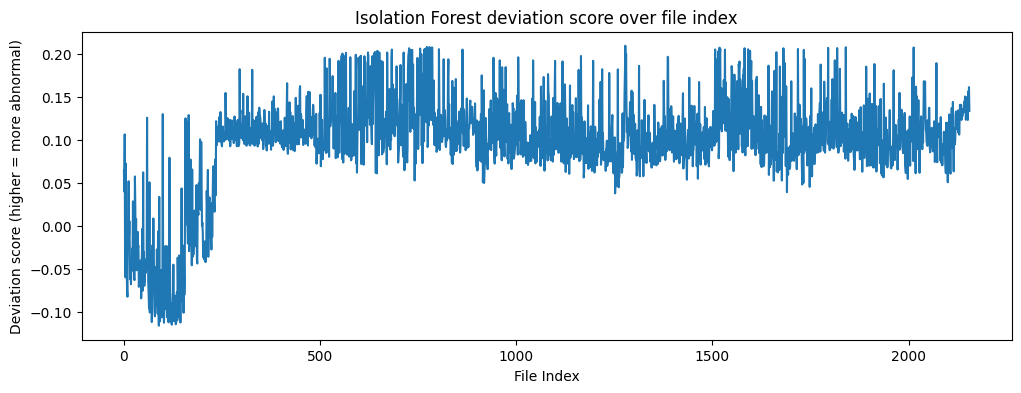

In [47]:
plt.figure(figsize=(12, 4))
plt.plot(df_features["file_index"], df_features["deviation_score"])
plt.title("Isolation Forest deviation score over file index")
plt.xlabel("File Index")
plt.ylabel("Deviation score (higher = more abnormal)")
plt.show()

The raw deviation score rises well before the end of the run, which suggests that the bearing begins to move away from healthy baseline behavior relatively early in its lifetime.

This is an important condition-monitoring result: degradation onset can occur significantly earlier than final failure. In other words, the model is not only reacting near the end of life, but is showing sensitivity to early abnormal change.

For this reason, the detected onset should be interpreted as an early-degradation signal rather than as a failure-time estimate.

## 11. Smooth the deviation score for trend interpretation

The raw deviation score fluctuates from file to file because each file is only a short vibration snapshot. To make the long-term trend easier to interpret, a rolling mean is applied.

In this notebook, a trailing rolling window of length 25 is used. This produces a smoother estimate of how abnormal the bearing behavior is over time.

The purpose of this step is not to change the model output, but to reduce sensitivity to isolated file-level fluctuations. A single spike in the raw score does not necessarily indicate meaningful degradation, whereas a sustained elevation in the smoothed score is more consistent with persistent abnormal behavior.

This smoothing is therefore used for visualization and onset interpretation only. The Isolation Forest itself is trained on the original scaled feature vectors, not on the smoothed score.

In [48]:
smooth_window = 25

df_features["deviation_score_smooth"] = (
    df_features["deviation_score"]
    .rolling(window=smooth_window, min_periods=1)
    .mean()
)

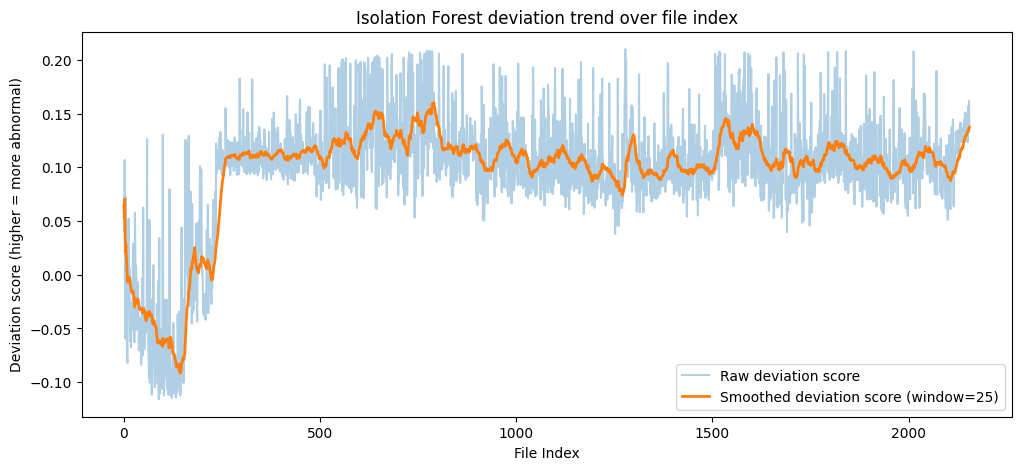

In [49]:
plt.figure(figsize=(12, 5))
plt.plot(df_features["file_index"], df_features["deviation_score"], alpha=0.35, label="Raw deviation score")
plt.plot(df_features["file_index"], df_features["deviation_score_smooth"], linewidth=2, label=f"Smoothed deviation score (window={smooth_window})")
plt.title("Isolation Forest deviation trend over file index")
plt.xlabel("File Index")
plt.ylabel("Deviation score (higher = more abnormal)")
plt.legend()
plt.show()

## 12. Define a healthy-based onset threshold and detect sustained degradation onset

The smoothed deviation score is now used to estimate when abnormal behavior begins in a sustained way.

First, a threshold is computed using only the healthy baseline portion of the smoothed score. In this notebook, the 99th percentile of the healthy smoothed scores is used. This gives a data-driven upper bound for normal behavior while remaining tied only to the healthy reference region.

Next, degradation onset is defined as the first sustained threshold crossing after the healthy baseline ends. The search begins only after the healthy region so that onset is not detected inside the data already assumed to be healthy.

A sustained crossing is used instead of a single threshold exceedance because one isolated spike may be caused by noise or temporary fluctuation. Requiring multiple consecutive files above the threshold makes the onset estimate more consistent with persistent abnormal behavior.

The resulting onset index is therefore interpreted as the earliest point at which the bearing begins to deviate from healthy baseline behavior in a sustained and measurable way.

In [77]:
healthy_smooth_scores = df_features.loc[:n_healthy - 1, "deviation_score_smooth"]
onset_threshold = np.percentile(healthy_smooth_scores, 99)

print("Healthy-based onset threshold:", onset_threshold)

Healthy-based onset threshold: 0.050775531916000885


In [78]:
sustain_len = 10
smooth_vals = df_features["deviation_score_smooth"].values

onset_index = None
search_start = n_healthy  # do not allow onset inside healthy baseline

for i in range(search_start, len(smooth_vals) - sustain_len + 1):
    if np.all(smooth_vals[i:i + sustain_len] > onset_threshold):
        onset_index = i
        break

print("Detected degradation onset index:", onset_index)

Detected degradation onset index: 243


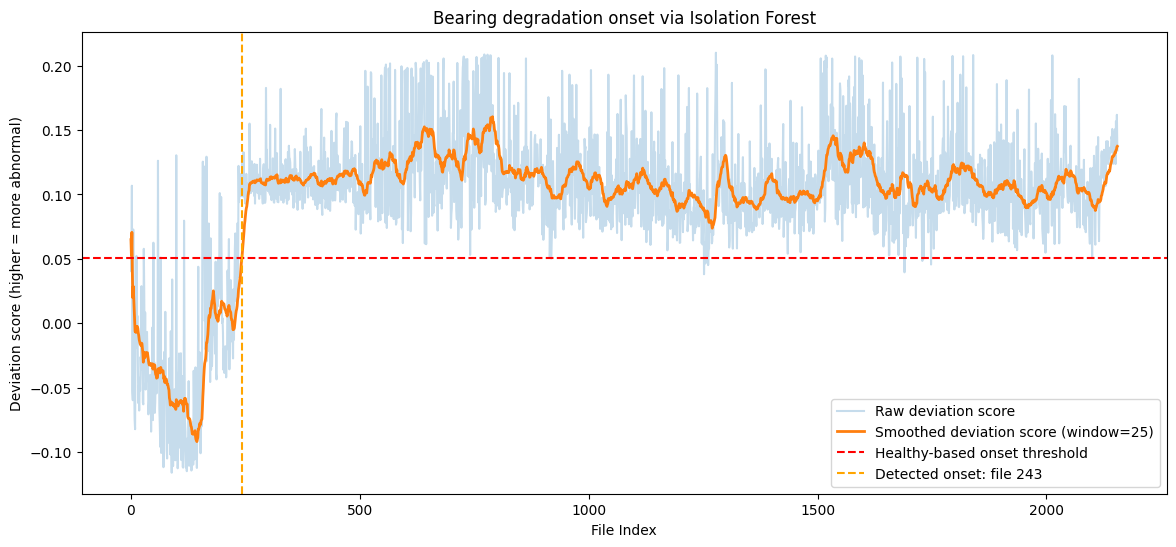

In [71]:
plt.figure(figsize=(14, 6))
plt.plot(df_features["file_index"], df_features["deviation_score"], alpha=0.25, label="Raw deviation score")
plt.plot(df_features["file_index"], df_features["deviation_score_smooth"], linewidth=2, label=f"Smoothed deviation score (window={smooth_window})")
plt.axhline(onset_threshold, color="red", linestyle="--", label="Healthy-based onset threshold")

if onset_index is not None:
    plt.axvline(onset_index, color="orange", linestyle="--", label=f"Detected onset: file {onset_index}")

plt.title("Bearing degradation onset via Isolation Forest")
plt.xlabel("File Index")
plt.ylabel("Deviation score (higher = more abnormal)")
plt.legend()
plt.show()

## 13. Final run summary

The final pipeline was run using channel 1, which gave the strongest overall degradation story among the tested channels.

Using early-life files as the healthy baseline, the Isolation Forest detected a sustained increase in deviation beginning around file 243. This indicates that, from that point onward, the bearing's vibration-feature behavior is no longer consistent with healthy operation in a persistent way.

The importance of this result is that it turns raw vibration measurements into an interpretable condition-monitoring signal. Instead of waiting for obvious end-of-life behavior or full failure, the pipeline identifies when the system begins to leave its healthy regime in a measurable and sustained way. This is the practical value of condition monitoring: detecting abnormal change early enough to support monitoring, inspection, and maintenance decisions.

In practical terms, this analysis makes it possible to track bearing health relative to a healthy reference state, identify which vibration indicators are most sensitive to degradation, and detect sustained abnormal behavior well before final failure. It transforms raw sensor data into a maintenance-relevant early-warning signal.

This result should therefore be interpreted as the onset of measurable degradation relative to the healthy baseline. It is not an exact failure time, not a fault-classification result, and not a remaining useful life prediction. Its strength is that it provides an interpretable early-warning signal from vibration data.

In [72]:
print("Current channel used:", channel_idx)
print("Detected degradation onset index:", onset_index)

Current channel used: 1
Detected degradation onset index: 243
